---
title: "Calderbank & Moo-Young: one regime split, two powers of the diffusivity, and the arithmetic that does not close"
description: "The correlation that says k_L depends on nothing but the physical properties, written twice: once for rigid interfaces with Sc^-2/3 and once for mobile ones with Sc^-1/2. This page reproduces the authors' own two theoretical derivations of the small-bubble constant from scratch, rebuilds the exponent split as a pymrm boundary layer and maps the transition between the two that the paper only sketches, and reports the two places where the paper's own printed arithmetic does not close: eq. (6) cannot produce eq. (7), and eq. (9) does not meet Chilton-Colburn where the paper says it does."
categories: [sec:A, struct:S3, struct:S4, tier:T0, data:tier6, phase:gas-liquid]
date: 2026-08-05
---

# Calderbank & Moo-Young: one regime split, two powers of the diffusivity

**Catalog ID:** `A3.6` · **Structures:** `S3` (1D steady BVP), `S4` (1D marched PDE) · **Tier:** T0

Calderbank & Moo-Young's result is one sentence long: in a dispersion whose
particles move freely under gravity, the continuous-phase mass-transfer
coefficient depends on **nothing but the physical properties**: not on bubble
size, not on slip velocity, not on agitator power. They write it twice, because
there are two regimes:

$$k_L\,N_{Sc}^{2/3} = 0.31\left(\frac{\Delta\rho\,\mu_c\,g}{\rho_c^{2}}\right)^{1/3}
\quad\text{(1)}\qquad\qquad
k_L\,N_{Sc}^{1/2} = 0.42\left(\frac{\Delta\rho\,\mu_c\,g}{\rho_c^{2}}\right)^{1/3}
\quad\text{(2)}$$

Eq. (1) is for bubbles below about 2½ mm, which "move in liquids as rigid
spheres under conditions of hindered flow in the boundary layer sense"; eq. (2)
is for bubbles above it, where "the conditions of unhindered flow envisaged by
HIGBIE obtained". **The entire content of the split is the exponent on the
Schmidt group**: $2/3$ against $1/2$, i.e. $k_L \propto D^{2/3}$ against
$k_L \propto D^{1/2}$.

A single evaluation point sits on one branch and can say nothing about the
other, so this page does four separate things.

1. **Reproduces the two derivations the authors do themselves**, in the note
   added in proof, of the constant in eq. (1): Froessling combined with Allen's
   rise velocity (they print 0.28) and Friedlander combined with Stokes' law
   (they print 0.34). Neither is a fit.
2. **Rebuilds the exponent split in pymrm** as a concentration boundary layer
   over an interface that is either held still or allowed to move, recovers
   $2/3$ and $1/2$ from the solved fields, and checks the magnitudes against two
   closed forms, each grid axis on its own refinement ladder.
3. **Maps the transition**, which the paper describes (its Fig. 3 and its
   remarks on surface-active agents) and never models. One dimensionless group
   controls it, and its halfway point is a root.
4. **Reports two places where the paper's own arithmetic does not close.**
   Eq. (6) as printed cannot produce eq. (7); and eq. (9) does not meet
   Chilton-Colburn at $N_{Re} = 10{,}000$, nor within ±12 %. Both are shown from
   the paper's own printed constants, with every alternative reading printed
   beside the printed one, and neither is repaired.

**Nothing here tests the three fitted constants.** 0.31, 0.42 and 0.13 are
regression lines drawn through Figs 1, 2 and 6, and the only way to judge them is
against the points in those figures. That is scoped out; see *The data*.

In [1]:
# Bootstrap: the pymrm this page was checked with, and the gallery files it was
# published with. Works in a checkout, in CI and on a fresh Colab VM.
GALLERY_REF = "main"  # replaced by the release tag at publication
PYMRM = ">=3.4.0,<4"  # equals meta.yaml pymrm_min_version, up to the next major
PAGE = "A3.6-calderbank-moo-young"  # equals the page directory

import os, sys, urllib.request
from pathlib import Path
_shared = next((p / "shared" for p in (Path.cwd(), *Path.cwd().parents)
                if (p / "shared" / "gallery_bootstrap.py").is_file()), None)
if _shared is None:
    _shared = (Path(os.environ.get("XDG_CACHE_HOME") or Path.home() / ".cache")
               / "pymrm-gallery" / GALLERY_REF)
    _shared.mkdir(parents=True, exist_ok=True)
    urllib.request.urlretrieve(
        "https://raw.githubusercontent.com/computational-chemical-engineering/"
        f"pymrm-gallery/{GALLERY_REF}/shared/gallery_bootstrap.py",
        _shared / "gallery_bootstrap.py")
sys.path.insert(0, str(_shared))
sys.modules.pop("gallery_bootstrap", None)
from gallery_bootstrap import setup
setup(PAGE, PYMRM, GALLERY_REF);  # the semicolon stops the cell echoing the path

In [2]:
import itertools
import time

import numpy as np
import pandas as pd
import sympy as sp
import matplotlib.pyplot as plt
from pymrm.checks import find_roots, observed_orders
from gallery_utils import load_data, load_meta, cite_data, Claims
from model import sh_sphere, BoundaryLayer, leveque, higbie

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})
claims = Claims(PAGE.split("-")[0])
T_START = time.time()

## Background

### What the paper set out to do

By 1960 the Froessling and Higbie pictures of interphase mass transfer both
existed and neither had been tested on gas-liquid dispersions, for a simple
reason: nobody could measure interfacial area in a bubble swarm, so nobody could
separate $k_L$ from $k_L a$. Calderbank's preceding work supplied the missing
half: a light-transmission method for interfacial area, a light-reflection
method for optically dense dispersions, and a γ-ray transmission method for gas
hold-up, from which the Sauter mean bubble size follows. With area in hand, $k_L$
in a swarm becomes measurable.

The paper's finding is stated flatly on journal page 42:

> It will be seen that both correlations show that the liquid phase mass transfer
> coefficients are independent of bubble size and slip velocity and depend only
> on the physical properties of the system.

and the mechanism, on page 41:

> It was concluded that small "rigid-sphere" bubbles experienced friction drag
> causing hindered flow in the boundary layer sense, and that under these
> circumstances the mass transfer coefficient was proportional to the 2/3 power
> of the diffusion coefficient, as found by FROESSLING and others. For large
> bubbles (> 2½ mm diameter) form drag predominated and the conditions of
> unhindered flow envisaged by HIGBIE obtained, and as postulated by HIGBIE the
> mass transfer coefficient was proportional to the ½ power of the diffusion
> coefficient.

So the split is not a curve-fitting convenience. It is a claim about which of two
mechanisms is operating, and the discriminating evidence is a **power of $D$**.

### Where this page's numbers come from, and the citation trap on this file

Every constant, exponent and stated result used here was read off `pdftoppm`
renders of the Elsevier scan at 300 ppi, which is that scan's native
resolution (`pdfimages -list` reports every image as CCITT-G4 bilevel at
300×300 ppi). Every numeric was **cropped and re-read at digit scale**, because
the 1961 Pergamon typesetting sets the decimal point as a *mid-dot* and this scan
drops most of them: `0·31` comes back from the text layer as `0 31`, and the
English abstract's copy of the turbulence correlation is OCR-ed as `0 18` where
the French and German abstracts of the same equation both print `0,13`.

**The text layer of this PDF states the wrong year and the wrong volume.** Its
first line comes back from `pdftotext` as

```
Chemcal   En@neenng Snence, 1981,   1'01        19, pp   39 to 54
```

The header **on the page image**, cropped at 300 ppi and enlarged with
nearest-neighbour interpolation, reads

> Chemical Engineering Science, 1961, Vol 16, pp 39 to 54  Pergamon Press Ltd,
> London  Printed in Great Britain

and the running footer on journal pages 44, 47, 49 and 51 independently reads
*"Chem Engng Sci Vol 16, Nos 1 and 2 December, 1961"*, of which the text layer
corrupts one to 1991. The publisher PII `0009-2509(61)87005-X` encodes 61 and the
page range 39-54 matches. **The citation on this page was established from the
article's own printed header on an image**, not from the text layer, the
filename or the PII.

### What this paper prints as numbers, and what lives only in figures

| Printed as a number | Lives only in a figure |
|---|---|
| Eqs. (1), (2), (4): the three correlation constants | Figs 1, 2, 6: the several hundred points behind them |
| $N_{Sh} = N_{Nu} = 2.0 + 0.31\,N_{Ra}^{1/3}$ (page 44) | Fig. 3: the transition region, one system per curve |
| The packed-bed chain: eq. (5), Chu's $\Delta p$, eqs. (6), (7), (8) | Fig. 4: transition-region froth data |
| The pipe chain: Blasius, eq. (9), Chilton-Colburn, and two claims about how they compare | Fig. 5: $k_La$ on sieve trays |
| Eq. (10) and the four competing suspension-power laws | |
| The note added in proof: Allen's ¼, Friedlander's 0.89, and the resulting 0.28 and 0.34 | |
| Baird's theoretical $K_L = 0.975\,D_L^{1/2}(g/d)^{1/4}$ | |
| The Range of Variables table: $k_L$, $D_L$, $\Delta\rho$, $\rho_c$, $\mu_c$, $d$ per data set | |

**No figure is digitised on this page.** Everything checked here is printed. The
one thing the figures could settle, whether 0.31, 0.42 and 0.13 are good fits, is
therefore *not settled here*.

## The published model

### The two correlations, and the one identity joining them

With $N_{Sc} = \mu_c/(\rho_c D_L)$, $\Delta\rho$ the phase density difference and
$g$ gravity, the paper's eqs. (1) and (2) are

$$k_L\,N_{Sc}^{2/3} = \frac{h_c}{C_P\rho_c}N_{Pr}^{2/3}
  = 0.31\left(\frac{\Delta\rho\,\mu_c\,g}{\rho_c^{2}}\right)^{1/3},\qquad
k_L\,N_{Sc}^{1/2} = 0.42\left(\frac{\Delta\rho\,\mu_c\,g}{\rho_c^{2}}\right)^{1/3}.$$

The heat-transfer half of eq. (1) is the Chilton-Colburn analogue and is not
separately checked here. On page 44 eq. (1) appears in a "more precise form"
that adds the stagnant limit,

$$N_{Sh} = N_{Nu} = 2.0 + 0.31\,N_{Ra}^{1/3},$$

with $N_{Ra} = N_{Gr}N_{Sc}$. Its second term is eq. (1) written again; the
notebook checks that equivalence as a transcription check. The `2.0` is the
conduction limit of a sphere in a stagnant medium and is reproduced with pymrm
below.

### The turbulence branch, and the two chains built on it

Where the dispersed phase is *not* free to move under gravity, the paper switches
to Kolmogoroff local isotropy and finds

$$k_L\,N_{Sc}^{2/3} = 0.13\left[\frac{(P/v)\,\mu_c}{\rho_c^{2}}\right]^{1/4}
\tag{4}$$

"with a standard deviation of 66 per cent" over a figure spanning $10^7$ in its
variables. Eq. (4) is then pushed through two closures the authors did not fit.

**Packed beds.** The flow work per unit volume of fluid is
$P/v = (\Delta p/L)\,G/(\rho_c\Sigma)$ (eq. 5), with $\Sigma$ the voidage; Chu's
correlation gives $\Delta p/L$; the two combine to a printed $P/v$; that goes into
eq. (4) to give eq. (6); and setting $\Sigma = 0.41$ gives eq. (7),
$j_d = 0.69\,N_{Re}^{-1/3}$, to be compared with Fallat's measured
$j_d = 0.626\,N_{Re}^{-0.322}$.

**Pipes.** The Blasius equation gives $\Delta p$; the same route gives eq. (9),
$j_{d,h} = 0.058\,N_{Re}^{-0.31}$, to be compared with Chilton-Colburn's
$j_{d,h} = 0.023\,N_{Re}^{-0.20}$.

Both chains are algebra on printed constants, so **both can be re-run exactly**.

### What the authors derive for eq. (1) without fitting anything

The note added in proof (journal pages 52-53) derives correlation (1) from
Froessling's equation combined with Allen's free-rise velocity

$$V = \tfrac14\left(\frac{\Delta\rho^{2}g^{2}}{\rho_c\mu_c}\right)^{1/3} d,$$

whereupon "a constant of 0·28 instead of 0·31, as proposed, is thereby obtained";
and again from Stokes' law combined with Friedlander's Stokes-region result
$N_{Sh} = 0.89\,(dV/D_L)^{1/3}$, "when a constant of 0·34 is obtained". Those are
predictions, not fits, and this page reproduces both.

## Parameters and assumptions

**Units.** The paper is CGS throughout: $k_L$ in cm/s, $D_L$ in cm²/s, densities
in g/cm³, viscosity in cP (converted to poise where it enters).

**Constants from outside this paper**, each named where it is used:

| Constant | Value | Source | Used for |
|---|---|---|---|
| Froessling's coefficient | 0.552 | Froessling (1938), the paper's ref. [4], **not printed in this article** | reproducing the printed 0.28 |
| Stokes' law denominator | 18 | $V = g\Delta\rho d^2/(18\mu_c)$ | reproducing the printed 0.34 |
| Allen's drag law | $C_D = 10\,N_{Re}^{-1/2}$ | Allen (1900), the paper's ref. [49] | *checking* the paper's printed ¼, not replacing it |
| gravity | 981 cm/s² | | every correlation |
| water | $\Delta\rho = 1$ g/cm³, $\mu = 1$ cP, $\rho = 1$ g/cm³ | room temperature | the Baird comparison |

The Froessling route is computed in both directions: forward from 0.552, and
inverted, so that the paper's own two printed numbers (0.28 and ¼) say what
coefficient they imply.

**The boundary-layer model's assumptions:**

- A flat interface of contact length $L$, with the solute saturated at the
  interface ($c = c^*$) and the liquid clean at entry. This is the *local*
  picture the paper's two mechanisms describe; it is not a bubble.
- A velocity field $u(y) = u_s + \dot\gamma\,y$ parallel to the interface, with
  $v = 0$. This satisfies continuity exactly. $u_s = 0$ is the rigid, no-slip
  interface; $\dot\gamma = 0$ is the fully mobile one.
- Steady state, and streamwise diffusion neglected against streamwise
  convection (the high-Péclet boundary-layer ordering).

It is a *mechanism* model, not a bubble model: it can reproduce the two exponents
and the interpolation between them, not 0.31 or 0.42, which absorb bubble
geometry, slip velocity and swarm hydrodynamics.

In [3]:
G_CGS = 981.0                     # cm/s^2, not printed in the paper
EXT = {"froessling": 0.552,       # Froessling (1938), ref. [4]; not printed in this article
       "stokes_den": 18.0,        # Stokes' law V = g drho d^2 / (18 mu)
       "allen_cd": 10.0,          # Allen (1900), ref. [49]: C_D = 10 Re^(-1/2)
       "g": G_CGS}
WATER = {"drho": 1.00, "mu": 0.010, "rho": 1.000}   # g/cm3, poise, g/cm3; room temperature
# Printed on journal page 50 beside eq. (5) and in eq. (4), and not rows of the CSV:
# the P/v the paper prints for Chu's bed, 35.4 mu^0.44 (1-S)^1.44 G^2.56 /
# (d^1.44 rho^2 S^4), and the 1/4 power of eq. (4).
PV_PRINTED = {"c": sp.Rational(354, 10), "mu": sp.Rational(44, 100),
              "void": sp.Rational(144, 100), "G": sp.Rational(256, 100),
              "d": sp.Rational(144, 100), "S": 4}
EQ4_POWER = sp.Rational(1, 4)
D_EXP_SMALL = -6                  # the small-bubble D_L exponent this page shows is right

## The data

**Tier 6.** This paper contains no individual measurement. Several hundred $k_L$
values appear **only as points on Figs 1, 2 and 6**. What is printed is the
constants and exponents, a handful of statements the authors make about their own
algebra, and a table of the *range* of each variable per data set. Two CSVs are
committed, both transcriptions of printed numbers.

`calderbank-mooyoung-1961-printed-numbers.csv`: every constant, exponent and
stated result used on this page, with the equation or sentence it was read from.
The `kind` column separates **fitted** constants (0.31, 0.42, 0.13) from
**predicted** ones (0.28, 0.34, 2.0) and from constants **quoted** from elsewhere.
Every function below takes these as one dictionary, so a mis-read constant is one
changed entry.

`calderbank-mooyoung-1961-range-of-variables.csv`: the two `This work` rows of
the Range of Variables table on journal pages 42-43, the large-bubble row (eq. 2)
and the small-bubble/rigid-sphere row (eq. 1). They are *marginal* ranges, so a
correlation evaluated at the corners gives a **window** that should bracket the
printed $k_L$ window, nothing sharper. Eq. (2)'s constant was fitted to the very
runs whose window it is compared with: that comparison is a goodness of fit and a
transcription check, not a validation.

**No dataset from another gallery page is loaded here**, and no number from one
is used. `A3.1`, `A3.3` and `A3.4` are related and cited in *Reuse* as context.

In [4]:
PN = load_data("calderbank-mooyoung-1961-printed-numbers.csv", page=PAGE).set_index("id")
RV = load_data("calderbank-mooyoung-1961-range-of-variables.csv", page=PAGE).set_index("row_id")
for f in ("calderbank-mooyoung-1961-printed-numbers.csv",
          "calderbank-mooyoung-1961-range-of-variables.csv"):
    print(cite_data(load_meta(f, page=PAGE)))

READS = set()


class Printed(dict):
    """The printed numbers by id; every read is logged, so the page can list the
    rows that no check reads."""

    def __getitem__(self, key):
        READS.add(key)
        return dict.__getitem__(self, key)


P0 = Printed(PN["printed_value"].astype(float).to_dict())
print(f"\nPrinted numbers transcribed: {len(PN)} rows")
print(PN[["journal_page", "equation", "quantity", "printed_value", "kind"]]
      .to_string(max_colwidth=52))
print("\nRange of Variables, the two sides of the split:")
print(RV[["regime", "correlation", "kL_lo", "kL_hi", "D_L_lo_mant", "D_L_hi_mant",
          "D_L_exp_printed", "mu_c_lo", "mu_c_hi", "d_lo", "d_hi"]].to_string())

Calderbank, P. H.; Moo-Young, M. B. (1961) — Chemical Engineering Science 16(1-2) 39-54 — doi:10.1016/0009-2509(61)87005-X — table
Calderbank, P. H.; Moo-Young, M. B. (1961) — Chemical Engineering Science 16(1-2) 39-54 — doi:10.1016/0009-2509(61)87005-X — table

Printed numbers transcribed: 33 rows
                    journal_page  equation                                             quantity  printed_value               kind
id                                                                                                                               
c_eq1                         42       1.0  constant of the small-bubble / rigid-sphere corr...   3.100000e-01    fitted_constant
c_eq2                         42       2.0             constant of the large-bubble correlation   4.200000e-01    fitted_constant
exp_sc_eq1                    42       1.0  Schmidt-number exponent of the small-bubble corr...   6.666667e-01    theory_exponent
exp_sc_eq2                    42       2.0  Schmid

## The paper's algebra, as one function of the printed numbers

Every check of the paper's own algebra is one function, `algebra(P, X)`, of the
printed-number dictionary `P` and the external constants `X`. The break table
below calls it once per mis-read constant. Crossings are roots
(`pymrm.checks.find_roots` over the whole physical range, raising unless exactly
one root is found). The symbolic identities are evaluated with sympy at exact
rational points, so their residual is either exactly zero or a transcription
error.

In [5]:
def one_root(f, lo, hi, n_scan=48, log=True, xtol=1e-12):
    """The single root of ``f`` on ``[lo, hi]``; raises unless there is exactly one."""
    r = find_roots(f, lo, hi, n_scan=n_scan, log=log, xtol=xtol)
    if len(r["roots"]) != 1 or r["failed"]:
        raise RuntimeError(f"expected one root on [{lo:g}, {hi:g}]: {r['message']}")
    return float(r["roots"][0])


def kL_eq1(drho, mu, rho, D, P, X):
    """Eq. (1), CGS: k_L = 0.31 (drho mu g / rho^2)^(1/3) Sc^(-2/3)."""
    return P["c_eq1"] * (drho * mu * X["g"] / rho**2)**(1 / 3) * (mu / (rho * D))**(-P["exp_sc_eq1"])


def kL_eq2(drho, mu, rho, D, P, X):
    """Eq. (2), CGS: k_L = 0.42 (drho mu g / rho^2)^(1/3) Sc^(-1/2)."""
    return P["c_eq2"] * (drho * mu * X["g"] / rho**2)**(1 / 3) * (mu / (rho * D))**(-P["exp_sc_eq2"])


def corners(row, d_exp):
    """The property corners of a Range of Variables row (CGS; cP to poise)."""
    r = RV.loc[row]
    Ds = (r.D_L_lo_mant * 10.0**d_exp, r.D_L_hi_mant * 10.0**d_exp)
    return list(itertools.product((r.drho_lo, r.drho_hi), (r.mu_c_lo / 100, r.mu_c_hi / 100),
                                  (r.rho_c_lo, r.rho_c_hi), Ds))


def window(row, corr, d_exp, P, X):
    vals = [corr(*c, P, X) for c in corners(row, d_exp)]
    return min(vals), max(vals)


def sc_window(row, d_exp):
    sc = [mu / (rho * D) for _, mu, rho, D in corners(row, d_exp)]
    return min(sc), max(sc)


def symbolic_identities(P, pv=PV_PRINTED, eq4_power=EQ4_POWER):
    """Three transcription identities, as max |ratio - 1| at exact rational points.

    chu: eq. (5) applied to Chu's correlation against the printed P/v.
    eq10: eq. (1) equated with eq. (4) against the printed shape of eq. (10).
    ra: eq. (1) rewritten as a Sherwood number against page 44's 0.31 Ra^(1/3).
    """
    mu, S, G, d, rho, drho, g, D, Pv = sp.symbols("mu Sigma G d rho drho g D Pv", positive=True)
    q = lambda x: sp.nsimplify(x, rational=True)
    pts = ({mu: 2, S: sp.Rational(1, 3), G: 5, d: 7, rho: 11, drho: 3, g: 13, D: 17},
           {mu: sp.Rational(1, 7), S: sp.Rational(2, 5), G: 19, d: sp.Rational(3, 11),
            rho: 23, drho: sp.Rational(5, 2), g: 29, D: sp.Rational(1, 31)})
    resid = lambda expr: max(abs(float(sp.N(expr.subs(pt) - 1, 40))) for pt in pts)
    # eq. (5) + Chu, against the printed P/v
    dpdL = q(P["c_chu"]) * (mu * (1 - S) / (d * G))**q(P["a_chu"]) * G**2 * (1 - S) / (d * rho * S**3)
    pv_printed = (pv["c"] * mu**pv["mu"] * (1 - S)**pv["void"] * G**pv["G"]
                  / (d**pv["d"] * rho**2 * S**pv["S"]))
    chu = resid(dpdL * G / (rho * S) / pv_printed)
    # eq. (1) = eq. (4) solved for P/v, against const (g drho)^(4/3) mu^(1/3) rho^(-2/3)
    lhs1 = q(P["c_eq1"]) * (drho * mu * g / rho**2)**sp.Rational(1, 3)
    pv_sol = sp.solve(sp.Eq(lhs1, q(P["c_eq4"]) * (Pv * mu / rho**2)**eq4_power), Pv)[0]
    shape10 = (g * drho)**sp.Rational(4, 3) * mu**sp.Rational(1, 3) / rho**sp.Rational(2, 3)
    ratio10 = pv_sol / shape10
    const10 = float(ratio10.subs({drho: 1, mu: 1, g: 1, rho: 1}))
    eq10 = resid(ratio10 / const10) if np.isfinite(const10) else np.nan
    # eq. (1) as a Sherwood number against 0.31 Ra^(1/3), Ra = d^3 drho g / (mu D)
    k1 = lhs1 * (mu / (rho * D))**(-q(P["exp_sc_eq1"]))
    ra = resid(k1 * d / D / (q(P["c_ra"]) * (d**3 * drho * g / (mu * D))**sp.Rational(1, 3)))
    return {"chu_identity_resid": chu, "eq10_exponent_resid": eq10,
            "ra_form_resid": ra, "_eq10_const": const10}


def algebra(P, X=EXT, d_exp_small=D_EXP_SMALL, water=WATER, pv=PV_PRINTED,
            eq4_power=EQ4_POWER, skip=()):
    """Every check of the paper's algebra, from the printed numbers ``P``."""
    out = {}
    # the two theoretical derivations of eq. (1)'s constant
    out["c28_value"] = X["froessling"] * np.sqrt(P["c_allen"])
    out["c28_rel_dev"] = out["c28_value"] / P["c_froessling_allen"] - 1
    out["froessling_implied_by_paper"] = P["c_froessling_allen"] / np.sqrt(P["c_allen"])
    out["froessling_implied_rel_dev"] = out["froessling_implied_by_paper"] / X["froessling"] - 1
    out["allen_quarter_from_drag_law"] = (2.0 / (3.0 * X["allen_cd"] / 2.0))**(2 / 3)
    out["allen_quarter_rel_dev"] = out["allen_quarter_from_drag_law"] / P["c_allen"] - 1
    out["c34_value"] = P["c_friedlander"] * (1.0 / X["stokes_den"])**(1 / 3)
    out["c34_rel_dev"] = out["c34_value"] / P["c_stokes_fried"] - 1
    out["theory_brackets_fitted"] = bool(out["c28_value"] < P["c_eq1"] < out["c34_value"])
    out["_bracket_margin"] = min(P["c_eq1"] / out["c28_value"] - 1, 1 - P["c_eq1"] / out["c34_value"])
    # the crossing of eqs (1) and (2) in Sc, and the Sc windows of the two data sets
    de = P["exp_sc_eq1"] - P["exp_sc_eq2"]
    out["crossover_Sc"] = (P["c_eq2"] / P["c_eq1"])**(1 / de) if de > 0 else np.nan
    sc_win = {"this_work_large": sc_window("this_work_large",
                                           int(RV.loc["this_work_large", "D_L_exp_printed"])),
              "this_work_small": sc_window("this_work_small", d_exp_small)}
    sc_min = np.array([w[0] for w in sc_win.values()])
    out["_sc_win"] = sc_win
    out["data_sc_min_over_crossover"] = sc_min.min() / out["crossover_Sc"]
    out["data_sc_windows_above_crossover"] = int(np.sum(sc_min > out["crossover_Sc"]))
    out["_sc_margin"] = float(np.min(np.abs(sc_min / out["crossover_Sc"] - 1)))
    for tag, s in zip(("min", "max"), sc_win["this_work_large"]):
        out[f"eq2_over_eq1_large_row_sc_{tag}"] = (P["c_eq2"] / P["c_eq1"]) * s**de
    # the small-bubble D_L exponent: the control, and three candidates
    e_large = int(RV.loc["this_work_large", "D_L_exp_printed"])
    lo2, hi2 = window("this_work_large", kL_eq2, e_large, P, X)
    out["eq2_window_lo_over_printed"] = lo2 / RV.loc["this_work_large", "kL_lo"]
    out["eq2_window_hi_over_printed"] = hi2 / RV.loc["this_work_large", "kL_hi"]
    top = {e: window("this_work_small", kL_eq1, e, P, X)[1] / RV.loc["this_work_small", "kL_hi"]
           for e in (-4, -5, -6)}
    out["_top"] = top
    out["eq1_window_hi_printed_exponent"] = top[int(RV.loc["this_work_small", "D_L_exp_printed"])]
    out["eq1_window_hi_exponent_5"] = top[-5]
    out["eq1_window_hi_over_printed"] = window("this_work_small", kL_eq1, d_exp_small, P, X)[1] \
        / RV.loc["this_work_small", "kL_hi"]
    dist = sorted((abs(np.log(v)), e) for e, v in top.items())
    out["small_row_exponent_selected"] = int(dist[0][1])
    out["_exponent_margin"] = dist[1][0] - dist[0][0]
    # the symbolic identities, and eq. (10)'s constant
    sym = symbolic_identities(P, pv, eq4_power)
    out.update({k: v for k, v in sym.items() if not k.startswith("_")})
    out["eq10_implied_const"] = sym["_eq10_const"]
    # the packed-bed chain
    out["eq6_prefactor_derived"] = P["c_eq4"] * P["c_chu"]**0.25
    out["eq6_prefactor_rel_dev"] = out["eq6_prefactor_derived"] / P["c_eq6"] - 1
    S = P["sigma_fallat"]
    chain_exp = (1 + P["a_chu"]) / 4                  # (1-S) and Re exponents of the chain
    jd = {"printed_eq6": P["c_eq6"] * ((1 - S) / S)**(1 / 3),
          "sigma_inverse": P["c_eq6"] * (1 - S)**(1 / 3) / S,
          "chain": out["eq6_prefactor_derived"] * (1 - S)**chain_exp / S}
    out["_jd"], out["_chain_exp"] = jd, chain_exp
    out["eq7_from_printed_eq6_rel_dev"] = jd["printed_eq6"] / P["c_eq7"] - 1
    out["eq7_from_sigma_inverse_rel_dev"] = jd["sigma_inverse"] / P["c_eq7"] - 1
    re_f = np.geomspace(100.0, 10000.0, 201)          # the Reynolds numbers the page compares over
    fal = P["c_fallat"] * re_f**P["e_fallat"]
    out["fallat_dev_printed_eq7"] = float(np.max(np.abs(P["c_eq7"] * re_f**(-1 / 3) / fal - 1)))
    out["fallat_dev_sigma_inverse"] = float(np.max(np.abs(jd["sigma_inverse"] * re_f**(-1 / 3) / fal - 1)))
    out["fallat_dev_chain"] = float(np.max(np.abs(jd["chain"] * re_f**(-chain_exp) / fal - 1)))
    out["fallat_dev_eq8"] = float(np.max(np.abs(P["c_eq8"] * re_f**(-1 / 3) / fal - 1)))
    out["_re_f"] = re_f
    # the pipe chain, and the claim about Chilton-Colburn
    c9 = P["c_eq4"] * P["c_blasius"]**0.25
    e9_exact = -(1 / 16 + 1 / 4)
    out["eq9_prefactor_derived"] = c9
    out["eq9_prefactor_rel_dev"] = c9 / P["c_eq9"] - 1
    re_lo, re_hi, re_claim = P["re_lo_cc"], P["re_hi_cc"], P["re_agree_cc"]
    re_r = np.geomspace(re_lo, re_hi, 401)            # the stated range, ends included
    for tag, e9 in (("", P["e_eq9"]), ("_exact_exponent", e9_exact)):
        dev = lambda Re, e9=e9: c9 * Re**e9 / (P["c_cc"] * Re**P["e_cc"]) - 1
        try:
            out[f"pipe_cross_Re{tag}"] = one_root(dev, 1.0, 1e9)
        except RuntimeError:
            out[f"pipe_cross_Re{tag}"] = np.nan
        out[f"pipe_maxdev_over_range{tag}"] = float(np.max(np.abs(dev(re_r))))
        if not tag:
            out["pipe_dev_at_claimed_Re"] = dev(re_claim)
            out["pipe_maxdev_paper_direction"] = float(np.max(np.abs(1 / (1 + dev(re_r)) - 1)))
            out["_dev_lo"], out["_dev_hi"] = dev(re_lo), dev(re_hi)
    x = out["pipe_cross_Re"]
    out["pipe_claim_over_cross"] = re_claim / x
    out["pipe_deviation_changes_sign_in_range"] = bool(re_lo < x < re_hi)
    out["_sign_margin"] = (min(np.log(x / re_lo), np.log(re_hi / x)) / np.log(re_hi / re_lo)
                           if np.isfinite(x) else np.nan)
    out["pipe_maxdev_exceeds_claim"] = bool(out["pipe_maxdev_over_range"] > P["maxdev_cc"] / 100)
    out["_maxdev_margin"] = abs(out["pipe_maxdev_over_range"] / (P["maxdev_cc"] / 100) - 1)
    # Baird's theoretical equation against eq. (2)
    if "baird" not in skip:
        def d_agree(drho, mu, rho):
            """Diameter (cm) where eq. (2) and K_L = 0.975 D^(1/2) (g/d)^(1/4) coincide."""
            k_over_sqrtD = kL_eq2(drho, mu, rho, 1.0, P, X)
            return X["g"] * (P["c_baird"] / k_over_sqrtD)**4
        r = RV.loc["this_work_large"]
        cases = {"row minimum viscosity": (r.drho_lo, r.mu_c_lo / 100, r.rho_c_hi),
                 "water": (water["drho"], water["mu"], water["rho"]),
                 "row maximum viscosity": (r.drho_hi, r.mu_c_hi / 100, r.rho_c_hi)}
        dstar = {k: d_agree(*v) for k, v in cases.items()}
        out["_dstar"] = dstar
        out["baird_cross_d_water_cm"] = dstar["water"]
        out["baird_cross_d_spread"] = dstar["row maximum viscosity"] / dstar["row minimum viscosity"]
        inside = [r.d_lo <= v <= r.d_hi for v in dstar.values()]
        out["n_baird_crossings_inside_row"] = int(sum(inside))
        out["_baird_margin"] = min(min(abs(np.log(v / r.d_lo)), abs(np.log(v / r.d_hi)))
                                   for v in dstar.values())
        DL = r.D_L_lo_mant * 10.0**int(r.D_L_exp_printed)
        k2 = kL_eq2(water["drho"], water["mu"], water["rho"], DL, P, X)
        out["baird_ratio_at_5cm"] = k2 / (P["c_baird"] * DL**0.5 * (X["g"] / P["d_baird_max"])**0.25)
        out["_baird_DL"] = DL
    return out


A = algebra(P0)
print("algebra evaluated:", len([k for k in A if not k.startswith("_")]), "quantities")

algebra evaluated: 47 quantities


## PyMRM implementation

Two linear models, both in `model.py`. The paper's own algebra carries most of
the validation; the pymrm work tests the one thing the algebra cannot reach, the
mechanism behind the exponents.

### 1. The stagnant limit: a sphere in a quiescent medium (`S3`)

$$\frac{1}{r^{2}}\frac{\mathrm d}{\mathrm d r}\!\left(r^{2}\frac{\mathrm d c}{\mathrm d r}\right)=0,
\qquad c(R)=c^*,\quad c(R_\infty)=0,$$

assembled from `construct_grad` and `construct_div(nu=2)` on cells spaced
geometrically from $R$ to $R_\infty = 10^4 R$, and solved with one sparse solve:
the problem is linear. The surface gradient is read with
`compute_boundary_values` under the solve's own boundary conditions. On this
finite shell the exact answer is $N_{Sh} = 2/(1 - R/R_\infty)$, so the stagnant
floor $N_{Sh}(1 - R/R_\infty)$ is the closed-form limit $R/R_\infty \to 0$ and
what remains is discretisation error. The geometry code `nu` is under test, and
the break table injects `nu=0` and `nu=1`.

### 2. The regime split: a concentration boundary layer (`S4`)

$$u(y)\,\frac{\partial c}{\partial x}=D_L\,\frac{\partial^{2}c}{\partial y^{2}},
\qquad u(y)=u_s+\dot\gamma\,y,$$

with $c(x,0)=c^*$, $c(0,y)=0$ and no flux at $y_{\max}$ (16 layer thicknesses).
The problem is **linear**, and it is marched in $x$ as a transient problem is
marched in time, with backward Euler: $u(y)$ is the accumulation coefficient,
built once with `construct_coefficient_matrix`, and the step matrix is factorised
once and reused at every step. The mean coefficient is the sum of the step fluxes
over $L$, each read with `compute_boundary_values`; the exit-plane balance
$\sum_i u_i V_i c_i / L$ is the same number up to the residual of the solves,
because backward Euler telescopes the diffusive divergence onto the boundary
faces.

- $u_s = 0$: rigid interface. The only length scale is
  $\delta_{\rm Lev}=(9D_LL/\dot\gamma)^{1/3}$, so $k_L \propto D_L^{2/3}$: the
  **Lévêque/Froessling** branch, eq. (1).
- $\dot\gamma = 0$: mobile interface. The only length scale is
  $\delta_{\rm H}=\sqrt{D_LL/u_s}$, so $k_L\propto D_L^{1/2}$: the **Higbie**
  branch, eq. (2).
- Both non-zero: the transition the paper's Fig. 3 shows and never models.

Backward Euler is first order in the step and the cell-centred diffusion
operator second order in the cell size; each is measured on its own ladder below.

In [6]:
RATIO, N_R, NR_LAD = 1e-4, 800, (100, 200, 400, 800, 1600)
D_REF, L_REF, GDOT, U_S = 1e-9, 1.0, 1.0, 1e-3     # SI; only ratios matter
N_PROD, LAD = 800, (200, 400, 800, 1600)
BRANCH = {"leveque": (dict(u_s=0.0, gdot=GDOT), leveque(D_REF, GDOT, L_REF)),
          "higbie": (dict(u_s=U_S, gdot=0.0), higbie(D_REF, U_S, L_REF))}
D_LEV = (9 * D_REF * L_REF / GDOT)**(1 / 3)        # the rigid-branch layer thickness


def bl(n_y, n_x, D=D_REF, interface="dirichlet", read="face", y_span=16.0, **flow):
    return BoundaryLayer(D=D, L=L_REF, n_y=n_y, y_span=y_span, **flow).run(n_x, interface, read)


print(f"Sh at R/R_inf = {RATIO:g}, {N_R} cells: {sh_sphere(RATIO, N_R):.8f}  "
      f"(exact {2 / (1 - RATIO):.8f})")

Sh at R/R_inf = 0.0001, 800 cells: 2.00013317  (exact 2.00020002)


## Results

### 1. The two theoretical derivations the authors do themselves

In [7]:
print("Froessling + Allen")
print(f"   forward : {EXT['froessling']} * sqrt({P0['c_allen']}) = {A['c28_value']:.6f}   "
      f"printed {P0['c_froessling_allen']}   rel {A['c28_rel_dev']:+.2%}")
print(f"   inverse : the paper's own {P0['c_froessling_allen']} and {P0['c_allen']} imply a "
      f"Froessling coefficient of {A['froessling_implied_by_paper']:.4f}, "
      f"{A['froessling_implied_rel_dev']:+.2%} on {EXT['froessling']}")
print(f"   Allen's {P0['c_allen']} recomputed from C_D = {EXT['allen_cd']:g} Re^(-1/2): "
      f"{A['allen_quarter_from_drag_law']:.4f} ({A['allen_quarter_rel_dev']:+.1%})")
print("\nFriedlander + Stokes")
print(f"   {P0['c_friedlander']} * (1/{EXT['stokes_den']:g})^(1/3) = {A['c34_value']:.6f}   "
      f"printed {P0['c_stokes_fried']}   rel {A['c34_rel_dev']:+.2%}")
print(f"\nThe two predictions bracket the fitted constant: {A['c28_value']:.3f} < "
      f"{P0['c_eq1']} < {A['c34_value']:.3f}: {A['theory_brackets_fitted']}")

Froessling + Allen
   forward : 0.552 * sqrt(0.25) = 0.276000   printed 0.28   rel -1.43%
   inverse : the paper's own 0.28 and 0.25 imply a Froessling coefficient of 0.5600, +1.45% on 0.552
   Allen's 0.25 recomputed from C_D = 10 Re^(-1/2): 0.2610 (+4.4%)

Friedlander + Stokes
   0.89 * (1/18)^(1/3) = 0.339599   printed 0.34   rel -0.12%

The two predictions bracket the fitted constant: 0.276 < 0.31 < 0.340: True


### 2. Where the two correlations cross, and where the data sit

Eqs. (1) and (2) differ only in the Schmidt exponent, so they give the same
$k_L$ at exactly one Schmidt number, $N_{Sc}^\star = (0.42/0.31)^{6}$. The paper
notices the crossing in words ("the mass transfer coefficients for large and
small bubbles approach each other at low values of the Schmidt group") but never
prints the number.

In [8]:
SC_STAR, SC_WIN = A["crossover_Sc"], A["_sc_win"]
print(f"N_Sc* = ({P0['c_eq2']}/{P0['c_eq1']})^6 = {SC_STAR:.4f}")
for row, (lo, hi) in SC_WIN.items():
    print(f"   {RV.loc[row, 'regime']:32s} Sc in [{lo:.4g}, {hi:.4g}]")
print(f"{A['data_sc_windows_above_crossover']} of 2 data sets lie wholly above N_Sc*; the lowest "
      f"Schmidt number of either is {A['data_sc_min_over_crossover']:.1f} times N_Sc*, so the "
      "crossing is an extrapolation of both lines.")
print(f"Over the large-bubble row's Schmidt window eq. (2) gives "
      f"{A['eq2_over_eq1_large_row_sc_min']:.2f} to {A['eq2_over_eq1_large_row_sc_max']:.2f} "
      "times eq. (1).")

N_Sc* = (0.42/0.31)^6 = 6.1848
   large bubbles                    Sc in [105.9, 4.579e+05]
   small bubbles and rigid spheres  Sc in [547.3, 2.782e+04]
2 of 2 data sets lie wholly above N_Sc*; the lowest Schmidt number of either is 17.1 times N_Sc*, so the crossing is an extrapolation of both lines.
Over the large-bubble row's Schmidt window eq. (2) gives 2.95 to 11.89 times eq. (1).


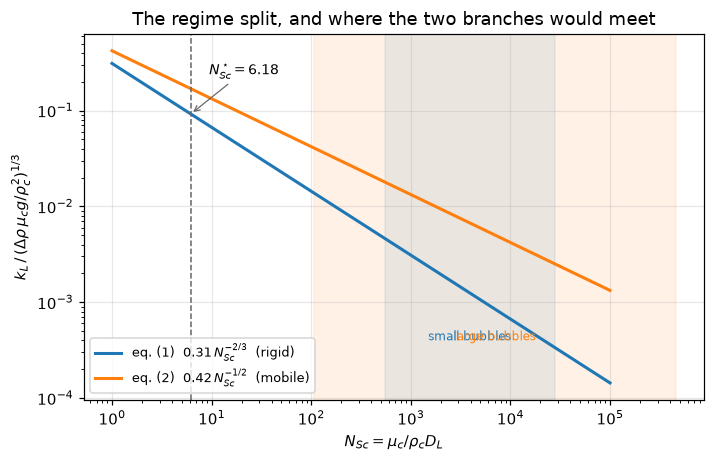

In [9]:
fig, ax = plt.subplots(figsize=(6.6, 4.3))
Sc = np.logspace(0, 5, 400)
ax.loglog(Sc, P0["c_eq1"] * Sc**(-2 / 3), lw=2, label=r"eq. (1)  $0.31\,N_{Sc}^{-2/3}$  (rigid)")
ax.loglog(Sc, P0["c_eq2"] * Sc**(-1 / 2), lw=2, label=r"eq. (2)  $0.42\,N_{Sc}^{-1/2}$  (mobile)")
ax.axvline(SC_STAR, color="0.4", ls="--", lw=1)
ax.annotate(rf"$N_{{Sc}}^\star={SC_STAR:.2f}$", (SC_STAR, P0["c_eq1"] * SC_STAR**(-2 / 3)),
            xytext=(12, 26), textcoords="offset points", fontsize=9,
            arrowprops=dict(arrowstyle="->", lw=0.8, color="0.4"))
for row, col in (("this_work_small", "tab:blue"), ("this_work_large", "tab:orange")):
    lo, hi = SC_WIN[row]
    ax.axvspan(lo, hi, color=col, alpha=0.10)
    ax.text(np.sqrt(lo * hi), 4e-4, RV.loc[row, "regime"].split(" and ")[0], ha="center",
            fontsize=8, color=col)
ax.set_xlabel(r"$N_{Sc}=\mu_c/\rho_c D_L$")
ax.set_ylabel(r"$k_L\,/\,(\Delta\rho\,\mu_c g/\rho_c^2)^{1/3}$")
ax.set_title("The regime split, and where the two branches would meet")
ax.legend(fontsize=8.5, loc="lower left")
fig.tight_layout()
plt.show()

### 3. The small-bubble row's diffusivity exponent

The test has a **control**: the same corner evaluation applied to the
large-bubble row, whose printed exponent is $-6$, using eq. (2). The control must
reproduce that row's printed $k_L$ window without adjustment, and the test must
be able to fail, which the printed $-4$ shows it can. Both comparisons are
goodness of fit (the constants were fitted to these runs); what they can see is a
wrong power of ten.

In [10]:
r_l, r_s = RV.loc["this_work_large"], RV.loc["this_work_small"]
print(f"CONTROL  large bubbles, eq. (2), D exponent as printed ({int(r_l.D_L_exp_printed)}):")
print(f"   window / printed: bottom {A['eq2_window_lo_over_printed']:.4f}, "
      f"top {A['eq2_window_hi_over_printed']:.4f}   (printed [{r_l.kL_lo}, {r_l.kL_hi}] cm/s)")
print("\nTEST  small bubbles and rigid spheres, eq. (1): top of the window / printed top")
for e, v in A["_top"].items():
    tag = "  <- as printed" if e == int(r_s.D_L_exp_printed) else ""
    print(f"   D x 10^{e:<3d} -> {v:8.4f}{tag}")
print(f"\nThe exponent whose window top lands nearest the printed ceiling (in log distance) is "
      f"{A['small_row_exponent_selected']}, by a margin of {A['_exponent_margin']:.2f} in ln.")
print(f"Everything below uses {D_EXP_SMALL}.")

CONTROL  large bubbles, eq. (2), D exponent as printed (-6):
   window / printed: bottom 0.8184, top 0.8964   (printed [0.007, 0.08] cm/s)

TEST  small bubbles and rigid spheres, eq. (1): top of the window / printed top
   D x 10^-4  ->  21.1832  <- as printed
   D x 10^-5  ->   4.5638
   D x 10^-6  ->   0.9832

The exponent whose window top lands nearest the printed ceiling (in log distance) is -6, by a margin of 1.50 in ln.
Everything below uses -6.


### 4. The packed-bed chain

Eq. (5) applied to Chu's correlation must give the $P/v$ the paper prints,
exponent for exponent; eq. (4) with that $P/v$ must give eq. (6); and eq. (6) at
$\Sigma = 0.41$ must give eq. (7). The chain forces the voidage group
$(1-\Sigma)^{(1+a)/4}\,\Sigma^{-1}$, with $a$ Chu's exponent, because $P/v$
carries $\Sigma^{-4}$ and eq. (4) takes its fourth root; eq. (6) prints
$((1-\Sigma)/\Sigma)^{1/3}$, the same exponent on both. Three readings are
carried: eq. (6) as printed, eq. (6) with $\Sigma^{-1}$, and the chain's own
exponents.

In [11]:
print(f"eq. (5) + Chu -> the printed P/v: largest |ratio - 1| at two rational points "
      f"below 1e-12 (here {A['chu_identity_resid']:.1e})")
print(f"eq. (6) prefactor: {P0['c_eq4']} * {P0['c_chu']}^(1/4) = {A['eq6_prefactor_derived']:.6f}   "
      f"printed {P0['c_eq6']}   rel {A['eq6_prefactor_rel_dev']:+.2%}")
print(f"the chain's voidage and Reynolds exponent: (1 + {P0['a_chu']})/4 = {A['_chain_exp']:.2f}")
jd = A["_jd"]
print(f"\nAt Sigma = {P0['sigma_fallat']}, against the printed eq. (7) constant {P0['c_eq7']}:")
print(f"   eq. (6) as printed   j_d = {jd['printed_eq6']:.4f} Re^(-1/3)   "
      f"{A['eq7_from_printed_eq6_rel_dev']:+.1%}")
print(f"   eq. (6), Sigma^-1    j_d = {jd['sigma_inverse']:.4f} Re^(-1/3)   "
      f"{A['eq7_from_sigma_inverse_rel_dev']:+.1%}")
print(f"   the chain            j_d = {jd['chain']:.4f} Re^(-{A['_chain_exp']:.2f})")
print("Neither reading of eq. (6) reaches eq. (7). Nothing is repaired.")
re_f = A["_re_f"]
print(f"\nAgainst Fallat's measured j_d = {P0['c_fallat']} Re^({P0['e_fallat']}), largest "
      f"|deviation| over Re = {re_f[0]:,.0f} to {re_f[-1]:,.0f} ({re_f.size} points; the "
      "ratio of two power laws is monotone, so it sits at an end):")
print(f"   printed eq. (7)        {A['fallat_dev_printed_eq7']:.1%}")
print(f"   eq. (6) with Sigma^-1  {A['fallat_dev_sigma_inverse']:.1%}")
print(f"   the chain              {A['fallat_dev_chain']:.1%}")
print(f"   eq. (8), {P0['c_eq8']} Re^(-1/3)  {A['fallat_dev_eq8']:.1%}   (Fallat re-fitted at the -1/3 slope)")
print("Eq. (7) is close to Fallat, but the printed eq. (6) does not produce it, and the "
      "reading that comes nearest is a little further from Fallat.")

eq. (5) + Chu -> the printed P/v: largest |ratio - 1| at two rational points below 1e-12 (here 0.0e+00)
eq. (6) prefactor: 0.13 * 35.4^(1/4) = 0.317098   printed 0.318   rel -0.28%
the chain's voidage and Reynolds exponent: (1 + 0.44)/4 = 0.36

At Sigma = 0.41, against the printed eq. (7) constant 0.69:
   eq. (6) as printed   j_d = 0.3590 Re^(-1/3)   -48.0%
   eq. (6), Sigma^-1    j_d = 0.6505 Re^(-1/3)   -5.7%
   the chain            j_d = 0.6396 Re^(-0.36)
Neither reading of eq. (6) reaches eq. (7). Nothing is repaired.

Against Fallat's measured j_d = 0.626 Re^(-0.322), largest |deviation| over Re = 100 to 10,000 (201 points; the ratio of two power laws is monotone, so it sits at an end):
   printed eq. (7)        4.6%
   eq. (6) with Sigma^-1  6.4%
   the chain              28.0%
   eq. (8), 0.67 Re^(-1/3)  3.6%   (Fallat re-fitted at the -1/3 slope)
Eq. (7) is close to Fallat, but the printed eq. (6) does not produce it, and the reading that comes nearest is a little further from

### 5. The pipe chain, and the claim about it

The same machinery on the Blasius equation is the **control** on the packed-bed
result: if the pipe chain reproduces, eq. (4)'s constant, the definition of $j_d$
and the flow-work argument are sound, and the packed-bed problem is localised to
the voidage. The paper then says eq. (9) "agrees with" Chilton-Colburn at
$N_{Re} = 10{,}000$ "with a maximum deviation of ±12 per cent" over 2000-20,000.
The crossing is a root; the largest deviation is evaluated over the whole stated
range.

In [12]:
print(f"eq. (9) prefactor: {P0['c_eq4']} * {P0['c_blasius']}^(1/4) = "
      f"{A['eq9_prefactor_derived']:.6f}   printed {P0['c_eq9']}   rel {A['eq9_prefactor_rel_dev']:+.3%}")
print(f"eq. (9) exponent : -(1/16 + 1/4) = {-(1 / 16 + 1 / 4):.4f}   printed {P0['e_eq9']}")
print(f"\nwith the printed exponent {P0['e_eq9']}:")
print(f"   crossing at N_Re = {A['pipe_cross_Re']:.0f} (the paper: {P0['re_agree_cc']:,.0f}, "
      f"{A['pipe_claim_over_cross']:.2f} times higher)")
print(f"   deviation at {P0['re_agree_cc']:,.0f}: {A['pipe_dev_at_claimed_Re']:+.2%}")
print(f"   deviation at {P0['re_lo_cc']:,.0f}: {A['_dev_lo']:+.2%},  at {P0['re_hi_cc']:,.0f}: "
      f"{A['_dev_hi']:+.2%}")
print(f"   largest |deviation| over the range {A['pipe_maxdev_over_range']:.1%} as (eq9 - CC)/CC, "
      f"{A['pipe_maxdev_paper_direction']:.1%} as (CC - eq9)/eq9")
print(f"with the exact exponent -5/16: crossing at {A['pipe_cross_Re_exact_exponent']:.0f}, "
      f"largest |deviation| {A['pipe_maxdev_over_range_exact_exponent']:.1%}")
print(f"\nThe deviation changes sign inside the stated range: "
      f"{A['pipe_deviation_changes_sign_in_range']}, so the paper's '+/-' is right about the "
      "shape; the size and the crossing are what its sentence gets wrong.")

eq. (9) prefactor: 0.13 * 0.0396^(1/4) = 0.057992   printed 0.058   rel -0.014%
eq. (9) exponent : -(1/16 + 1/4) = -0.3125   printed -0.31

with the printed exponent -0.31:
   crossing at N_Re = 4480 (the paper: 10,000, 2.23 times higher)
   deviation at 10,000: -8.45%
   deviation at 2,000: +9.28%,  at 20,000: -15.17%
   largest |deviation| over the range 15.2% as (eq9 - CC)/CC, 17.9% as (CC - eq9)/eq9
with the exact exponent -5/16: crossing at 3716, largest |deviation| 17.2%

The deviation changes sign inside the stated range: True, so the paper's '+/-' is right about the shape; the size and the crossing are what its sentence gets wrong.


### 6. Two more identities the paper's constants must satisfy

Eq. (10), the power that just suspends solids, follows from equating eqs. (1)
and (4). The paper prints its exponent structure and leaves the constant as
`const.`; the constant is recovered here. And page 44's $0.31\,N_{Ra}^{1/3}$
must be eq. (1) itself.

In [13]:
print(f"eq. (1) = eq. (4), solved for P/v, over (g drho)^(4/3) mu^(1/3) rho^(-2/3): "
      f"parameter-free to below 1e-12 (here {A['eq10_exponent_resid']:.1e})")
print(f"   the constant the paper leaves as 'const.': ({P0['c_eq1']}/{P0['c_eq4']})^4 = "
      f"{A['eq10_implied_const']:.4f}")
print(f"eq. (1) as a Sherwood number over {P0['c_ra']} Ra^(1/3): |ratio - 1| below 1e-12 "
      f"(here {A['ra_form_resid']:.1e})")

eq. (1) = eq. (4), solved for P/v, over (g drho)^(4/3) mu^(1/3) rho^(-2/3): parameter-free to below 1e-12 (here 0.0e+00)
   the constant the paper leaves as 'const.': (0.31/0.13)^4 = 32.3350
eq. (1) as a Sherwood number over 0.31 Ra^(1/3): |ratio - 1| below 1e-12 (here 0.0e+00)


### 7. Eq. (2) against the theory it says it represents

The note added in proof says eq. (2) "represents the data of BAIRD obtained with
spherical cap bubbles of equivalent diameters up to 5 cm **as well as the
theoretical equation proposed by this worker**",
$K_L = 0.975\,D_L^{1/2}(g/d)^{1/4}$. Eq. (2) contains no bubble diameter and
Baird's equation does, so they agree at exactly one diameter for a given liquid,
computable from the two printed constants.

In [14]:
print("Diameter at which eq. (2) and Baird's equation coincide:")
for k, v in A["_dstar"].items():
    where = "inside" if r_l.d_lo <= v <= r_l.d_hi else ("below" if v < r_l.d_lo else "above")
    print(f"   {k:24s} d* = {v:8.4f} cm   ({where} the row's {r_l.d_lo}-{r_l.d_hi} cm)")
print(f"{A['n_baird_crossings_inside_row']} of the {len(A['_dstar'])} crossings fall inside the "
      "diameters of the large-bubble runs; across the row's viscosity range d* moves by a "
      f"factor {A['baird_cross_d_spread']:.1f}.")
print(f"At Baird's largest bubble ({P0['d_baird_max']:g} cm) in water, with D_L = "
      f"{A['_baird_DL']:.2g} cm2/s, eq. (2) stands {A['baird_ratio_at_5cm']:.2f} times above his "
      "equation.")

Diameter at which eq. (2) and Baird's equation coincide:
   row minimum viscosity    d* =   0.1076 cm   (below the row's 0.2-0.8 cm)
   water                    d* =   0.1357 cm   (below the row's 0.2-0.8 cm)
   row maximum viscosity    d* =   2.3881 cm   (above the row's 0.2-0.8 cm)
0 of the 3 crossings fall inside the diameters of the large-bubble runs; across the row's viscosity range d* moves by a factor 22.2.
At Baird's largest bubble (5 cm) in water, with D_L = 1.9e-06 cm2/s, eq. (2) stands 2.46 times above his equation.


### 8. pymrm: the stagnant floor

The `2.0` of the page-44 form is the conduction limit of a sphere. The sphere is
solved on a ladder of nested geometric grids; orders come from successive
differences (`pymrm.checks.observed_orders`). The flux read at the surface and
the flux read at the outer shell (times the area ratio) agree to the residual of
the solve, which is the round-off scale the ladder differences are compared with.

In [15]:
def sphere_study(nu=2, outer="dirichlet", ns=NR_LAD, P=P0):
    """The stagnant floor on a ladder; the floor is Sh (1 - R/R_inf), its closed-form limit."""
    oo = observed_orders(lambda n: sh_sphere(RATIO, n, nu=nu, outer=outer), ns)
    floor = lambda sh: sh * (1 - RATIO)
    prod = sh_sphere(RATIO, N_R, nu=nu, outer=outer)
    shell = sh_sphere(RATIO, N_R, nu=nu, outer=outer, at="shell")
    vals = np.asarray(oo["values"])
    return {"sh_stagnant_rel_dev": floor(prod) / P["sh_floor"] - 1,
            "sh_richardson_rel_dev": abs(floor(oo["extrapolated"]) / P["sh_floor"] - 1),
            "sh_order_min": float(np.min(oo["orders"])), "sh_order_max": float(np.max(oo["orders"])),
            "sh_surface_vs_shell_flux": abs(prod / shell - 1) if shell != 0 else np.inf,
            "_finest_diff": abs(vals[-1] - vals[-2]) / abs(vals[-1]), "_oo": oo}


SPH = sphere_study()
for n, v in zip(NR_LAD, SPH["_oo"]["values"]):
    print(f"   n_r = {n:5d}   Sh(1 - R/R_inf) = {v * (1 - RATIO):.10f}   rel {v * (1 - RATIO) / 2 - 1:+.3e}")
print(f"observed orders {', '.join(f'{o:.4f}' for o in SPH['_oo']['orders'])}")
print(f"at {N_R} cells: {SPH['sh_stagnant_rel_dev']:+.2e} on the printed {P0['sh_floor']}; "
      f"Richardson limit below 1e-6 from it (here {SPH['sh_richardson_rel_dev']:.1e})")
print(f"surface flux against shell flux x area ratio: below 1e-9 "
      f"(here {SPH['sh_surface_vs_shell_flux']:.1e})")

   n_r =   100   Sh(1 - R/R_inf) = 1.9954833441   rel -2.258e-03
   n_r =   200   Sh(1 - R/R_inf) = 1.9989040875   rel -5.480e-04
   n_r =   400   Sh(1 - R/R_inf) = 1.9997303942   rel -1.348e-04
   n_r =   800   Sh(1 - R/R_inf) = 1.9999331581   rel -3.342e-05
   n_r =  1600   Sh(1 - R/R_inf) = 1.9999833603   rel -8.320e-06
observed orders 2.0496, 2.0269, 2.0140
at 800 cells: -3.34e-05 on the printed 2.0; Richardson limit below 1e-6 from it (here 6.0e-08)
surface flux against shell flux x area ratio: below 1e-9 (here 3.7e-13)


### 9. pymrm: the two branches against their closed forms

Each branch is solved at the production grid (800 cells, 800 steps) and on two
ladders: the step refined at 1600 cells, and the cells refined at 800 steps.
Successive differences cancel the other axis's fixed error, so each ladder gives
its own order. The Richardson limit in the step at 1600 cells still carries the
cell error of 1600 cells; subtracting that error, estimated from the cell
ladder, gives the two-axis limit, which is compared with the closed form. The
domain truncation is negligible by construction: the Lévêque profile at 16 layer
thicknesses is of order $e^{-16^3}$, the Higbie one of order
$\operatorname{erfc}(8)$; the domain study below measures it.

In [16]:
def bl_study(branch, flow=None, lad=LAD, read="face", y_span=16.0, interface="dirichlet"):
    flow_, exact = BRANCH[branch]
    flow = flow_ if flow is None else flow
    run = lambda ny, nx: bl(ny, nx, read=read, y_span=y_span, interface=interface, **flow)
    prod = run(N_PROD, N_PROD)
    ox = observed_orders(lambda n: run(lad[-1], n)["kbar"], lad)
    oy = observed_orders(lambda n: run(n, N_PROD)["kbar"], lad)
    y_err = oy["values"][-1] - oy["extrapolated"]
    k_xy = ox["extrapolated"] - y_err
    return {f"{branch}_rel_err_raw": prod["kbar"] / exact - 1,
            f"{branch}_rel_err_xy_extrap": abs(k_xy / exact - 1),
            f"{branch}_x_order_min": float(np.min(ox["orders"])),
            f"{branch}_x_order_max": float(np.max(ox["orders"])),
            f"{branch}_y_order_min": float(np.min(oy["orders"])),
            f"{branch}_y_order_max": float(np.max(oy["orders"])),
            f"{branch}_balance_gap": (abs(prod["kbar"] / prod["kbar_balance"] - 1)
                                      if prod["kbar_balance"] != 0 else np.nan),
            "_finest": (min(abs(ox["values"][-1] - ox["values"][-2]),
                            abs(oy["values"][-1] - oy["values"][-2])) / abs(prod["kbar"])
                        if prod["kbar"] != 0 else np.nan),
            "_ox": ox, "_oy": oy, "_exact": exact, "_prod": prod["kbar"]}


BLS = {b: bl_study(b) for b in BRANCH}
for b, s in BLS.items():
    print(f"{b}: at {N_PROD} x {N_PROD} rel {s[f'{b}_rel_err_raw']:+.3e}; flux sum against "
          f"exit-plane balance below 1e-9 (here {s[f'{b}_balance_gap']:.1e})")
    print(f"   step ladder (n_y = {LAD[-1]}), n_x = {LAD}: rel "
          f"{', '.join(f'{v / s['_exact'] - 1:+.3e}' for v in s['_ox']['values'])}; orders "
          f"{', '.join(f'{o:.4f}' for o in s['_ox']['orders'])}")
    print(f"   cell ladder (n_x = {N_PROD}), n_y = {LAD}: rel "
          f"{', '.join(f'{v / s['_exact'] - 1:+.3e}' for v in s['_oy']['values'])}; orders "
          f"{', '.join(f'{o:.4f}' for o in s['_oy']['orders'])}")
    print(f"   two-axis limit against the closed form: below 1e-7 "
          f"(here {s[f'{b}_rel_err_xy_extrap']:.1e})")
ROUNDOFF = max(SPH["sh_surface_vs_shell_flux"], *(BLS[b][f"{b}_balance_gap"] for b in BRANCH))
FINEST_OVER_ROUNDOFF = min(SPH["_finest_diff"], *(BLS[b]["_finest"] for b in BRANCH)) / ROUNDOFF
print(f"\nsmallest last difference of any ladder over the largest two-route gap of the solves: "
      f"at least 1e3 (here {FINEST_OVER_ROUNDOFF:.1e})")

leveque: at 800 x 800 rel -1.427e-04; flux sum against exit-plane balance below 1e-9 (here 2.8e-12)
   step ladder (n_y = 1600), n_x = (200, 400, 800, 1600): rel -5.562e-04, -2.787e-04, -1.398e-04, -7.041e-05; orders 0.9994, 0.9997
   cell ladder (n_x = 800), n_y = (200, 400, 800, 1600): rel -2.009e-04, -1.544e-04, -1.427e-04, -1.398e-04; orders 1.9999, 2.0000
   two-axis limit against the closed form: below 1e-7 (here 1.9e-08)
higbie: at 800 x 800 rel -1.600e-04; flux sum against exit-plane balance below 1e-9 (here 6.8e-12)
   step ladder (n_y = 1600), n_x = (200, 400, 800, 1600): rel -6.257e-04, -3.134e-04, -1.572e-04, -7.906e-05; orders 0.9997, 0.9998
   cell ladder (n_x = 800), n_y = (200, 400, 800, 1600): rel -2.164e-04, -1.713e-04, -1.600e-04, -1.572e-04; orders 1.9999, 1.9999
   two-axis limit against the closed form: below 1e-7 (here 1.2e-08)

smallest last difference of any ladder over the largest two-route gap of the solves: at least 1e3 (here 4.2e+05)


In [17]:
def domain_effect(spans=(16.0, 32.0)):
    """Relative change of the cell-extrapolated kbar when y_max goes from spans[0] to spans[1]."""
    out = []
    for b in BRANCH:
        k = [observed_orders(lambda n: bl(n, N_PROD, y_span=s, **BRANCH[b][0])["kbar"],
                             (400, 800, 1600))["extrapolated"] for s in spans]
        out.append(abs(k[1] / k[0] - 1))
    return max(out)


DOMAIN = domain_effect()
print(f"far field moved from 16 to 32 layer thicknesses, cell-extrapolated kbar of both "
      f"branches: largest relative change below 1e-8 (here {DOMAIN:.1e})")

far field moved from 16 to 32 layer thicknesses, cell-extrapolated kbar of both branches: largest relative change below 1e-8 (here 8.4e-11)


### 10. pymrm: the two exponents, and the transition between them

The exponent the paper reports is $\mathrm d\ln k_L/\mathrm d\ln D_L$ at fixed
$u_s$, $\dot\gamma$ and $L$. It is computed by a central difference in $\ln D_L$
with steps of $\ln 1.15$, on 400 cells and 400 steps. In each pure limit the grid
is scaled with the one layer thickness, so the discrete problem is self-similar
and the exponents are $2/3$ and $1/2$ to round-off: **they test the
implementation, not the physics**. What they catch is the wrong profile, and the
break table shows they do.

The transition is not fixed by dimensional analysis. With
$\Lambda = u_s/(\dot\gamma\,\delta_{\rm Lev})$, the halfway exponent $7/12$ and the
exponent within 10 % of the mobile end (of the span $2/3 - 1/2$) are roots over
$\Lambda = 10^{-3}$ to $10^{3}$. The finite-difference truncation and the grid
effect on the halfway root are measured by repeating it with half the difference
step and with twice the grid.

In [18]:
def d_ln_k_d_ln_D(u_s, gdot, n=400, rel=0.15, local=False, y_span=16.0):
    """Central difference of ln k in ln D at fixed u_s, gdot and L."""
    key = "k_local" if local else "kbar"
    k = [bl(n, n, D=D_REF * f, u_s=u_s, gdot=gdot, y_span=y_span)[key]
         for f in (1 / (1 + rel), 1 + rel)]
    return float(np.log(k[1] / k[0]) / (2 * np.log(1 + rel)))


N_HALF, N_MOBILE10 = 7 / 12, 0.5 + 0.1 * (2 / 3 - 0.5)


def transition(n=400, rel=0.15, local=False, y_span=16.0, which=("half", "mobile10")):
    expo = lambda lam: d_ln_k_d_ln_D(lam * GDOT * D_LEV, GDOT, n, rel, local, y_span)
    targets = {"half": N_HALF, "mobile10": N_MOBILE10}
    return {w: one_root(lambda lam: expo(lam) - targets[w], 1e-3, 1e3, n_scan=24, xtol=1e-8)
            for w in which}


EXP_RIGID = d_ln_k_d_ln_D(0.0, GDOT)
EXP_MOBILE = d_ln_k_d_ln_D(U_S, 0.0)
print(f"rigid  branch: d ln k / d ln D = 2/3 within 1e-9 (here {EXP_RIGID - 2 / 3:+.1e})")
print(f"mobile branch: d ln k / d ln D = 1/2 within 1e-9 (here {EXP_MOBILE - 0.5:+.1e})")

LAMS = np.array([0.0, 0.01, 0.03, 0.1, 0.2, 0.3, 0.5, 1.0, 2.0, 3.0, 10.0, 30.0, 100.0])
EXPS = np.array([d_ln_k_d_ln_D(l * GDOT * D_LEV, GDOT) for l in LAMS])
for l, e in zip(LAMS, EXPS):
    print(f"   Lambda = {l:8.3g}   d ln k / d ln D = {e:.4f}")
TR = transition()
TR_GRID = transition(n=800, which=("half",))
TR_FD = transition(rel=0.075, which=("half",))
LAM_HALF, LAM_90 = TR["half"], TR["mobile10"]
GRID_EFFECT = abs(TR_GRID["half"] / LAM_HALF - 1)
FD_EFFECT = abs(TR_FD["half"] / LAM_HALF - 1) * 4 / 3    # Richardson estimate of the O(h^2) truncation
print(f"\nhalfway (n = 7/12) at Lambda = {LAM_HALF:.5f}; within 10 % of the mobile end "
      f"(n = {N_MOBILE10:.4f}) at Lambda = {LAM_90:.4f}")
print(f"   grid: 800 cells and steps move the halfway root by below 1e-4 relative "
      f"(here {GRID_EFFECT:.1e})")
print(f"   difference step: truncation of the halfway root below 1e-4 relative "
      f"(here {FD_EFFECT:.1e})")

rigid  branch: d ln k / d ln D = 2/3 within 1e-9 (here -8.4e-12)
mobile branch: d ln k / d ln D = 1/2 within 1e-9 (here +1.5e-11)


   Lambda =        0   d ln k / d ln D = 0.6667
   Lambda =     0.01   d ln k / d ln D = 0.6617
   Lambda =     0.03   d ln k / d ln D = 0.6523
   Lambda =      0.1   d ln k / d ln D = 0.6254
   Lambda =      0.2   d ln k / d ln D = 0.5978
   Lambda =      0.3   d ln k / d ln D = 0.5786
   Lambda =      0.5   d ln k / d ln D = 0.5541
   Lambda =        1   d ln k / d ln D = 0.5272
   Lambda =        2   d ln k / d ln D = 0.5115
   Lambda =        3   d ln k / d ln D = 0.5066
   Lambda =       10   d ln k / d ln D = 0.5012
   Lambda =       30   d ln k / d ln D = 0.5002
   Lambda =      100   d ln k / d ln D = 0.5000



halfway (n = 7/12) at Lambda = 0.27205; within 10 % of the mobile end (n = 0.5167) at Lambda = 1.5067
   grid: 800 cells and steps move the halfway root by below 1e-4 relative (here 2.6e-05)
   difference step: truncation of the halfway root below 1e-4 relative (here 3.8e-05)


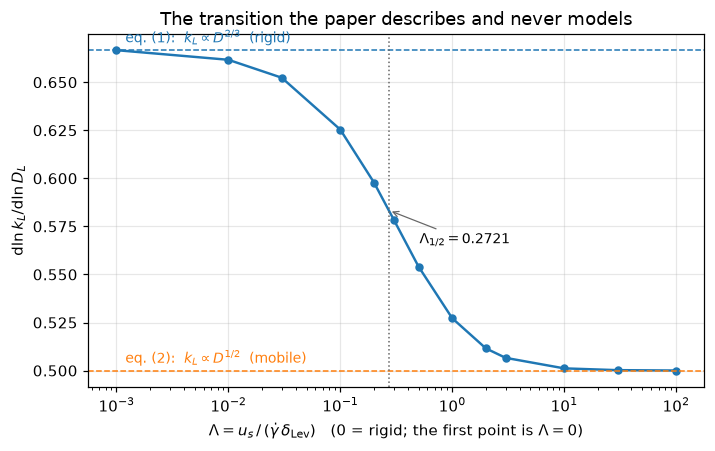

In [19]:
fig, ax = plt.subplots(figsize=(6.6, 4.2))
ax.semilogx(np.where(LAMS > 0, LAMS, 1e-3), EXPS, "o-", lw=1.6, ms=4.5)
ax.axhline(2 / 3, color="tab:blue", ls="--", lw=1)
ax.axhline(0.5, color="tab:orange", ls="--", lw=1)
ax.axvline(LAM_HALF, color="0.4", ls=":", lw=1)
ax.text(1.2e-3, 2 / 3 + 0.004, r"eq. (1):  $k_L\propto D^{2/3}$  (rigid)", color="tab:blue", fontsize=9)
ax.text(1.2e-3, 0.5 + 0.004, r"eq. (2):  $k_L\propto D^{1/2}$  (mobile)", color="tab:orange", fontsize=9)
ax.annotate(rf"$\Lambda_{{1/2}}={LAM_HALF:.4f}$", (LAM_HALF, N_HALF), xytext=(20, -22),
            textcoords="offset points", fontsize=9,
            arrowprops=dict(arrowstyle="->", lw=0.8, color="0.4"))
ax.set_xlabel(r"$\Lambda = u_s\,/\,(\dot\gamma\,\delta_{\rm Lev})$   (0 = rigid; the first point is $\Lambda=0$)")
ax.set_ylabel(r"$\mathrm{d}\ln k_L/\mathrm{d}\ln D_L$")
ax.set_title("The transition the paper describes and never models")
fig.tight_layout()
plt.show()

## Validation

### What is checked, and against what

| # | Check | Route A | Route B | What it can see |
|---|---|---|---|---|
| 1 | eq. (5) + Chu → the printed $P/v$ | sympy on Chu as printed | the printed $P/v$ | a mis-read constant or exponent |
| 2 | eq. (6) prefactor | $0.13\times35.4^{1/4}$ | printed 0.318 | a mis-read constant |
| 3 | eq. (9) prefactor and exponent | $0.13\times0.0396^{1/4}$, $-1/16-1/4$ | printed 0.058, $-0.31$ | a mis-read constant |
| 4 | eq. (7) from eq. (6) | two readings of the voidage group | printed 0.69 | **it fails** |
| 5 | eq. (9) against Chilton-Colburn | a root of the two power laws | the printed claim | **it fails** |
| 6, 7 | 0.28, 0.34 | Froessling × √Allen, Friedlander × $18^{-1/3}$ | the printed predictions | a mis-read or wrong external constant |
| 8 | $N_{Sh}\to 2$ | pymrm, `nu=2`, on a ladder | printed 2.0 | the wrong geometry or outer condition |
| 9, 10 | Lévêque, Higbie magnitudes | pymrm march, two-axis limit | closed forms | the wrong profile, interface or flux read |
| 11 | exponents 2/3, 1/2 | pymrm, from solved fields | printed exponents | **only a wrong profile**: dimensional analysis fixes them otherwise |
| 12 | eq. (1) and page 44's Rayleigh form | sympy | sympy | a mis-read exponent or constant |
| 13 | eq. (10) exponents | sympy on (1) and (4) | printed eq. (10) | a mis-read power |

**A break row establishes sensitivity, never correctness.** Every row below
injects a defect and watches a claim fail, so no row can catch a baseline that is
wrong rather than insensitive. That is why checks 6, 7, 9 and 10 exist: each
reaches a printed or exact number by a route that shares no code with what it is
compared against, and why the ladders, not the break table, bound the numerics.
Nothing on this page can see whether 0.31, 0.42 and 0.13 are good fits.

### Claims

Every number the page states, with how it is checked. The closed-form algebra is
held to `FIXED`; solver results are held to `SOLV`. Residuals, identities and
orders are bounds with their basis.

In [20]:
FIXED, SOLV = 1e-6, 1e-4


def value(name, x, rtol=FIXED, **kw):
    claims.value(name, x, rtol=rtol, **kw)


def bound(name, x, **kw):
    claims.bound(name, x, **kw)


# --- the two theoretical derivations --------------------------------------------------
for k in ("c28_value", "c28_rel_dev", "froessling_implied_by_paper", "froessling_implied_rel_dev",
          "allen_quarter_from_drag_law", "allen_quarter_rel_dev", "c34_value", "c34_rel_dev"):
    value(k, A[k])
claims.exact("theory_brackets_fitted", A["theory_brackets_fitted"], margin=A["_bracket_margin"],
             min_margin=0.01, note="0.276 < 0.31 < 0.340; margin the smaller relative gap")
# --- the split -----------------------------------------------------------------------------
value("crossover_Sc", A["crossover_Sc"])
value("data_sc_min_over_crossover", A["data_sc_min_over_crossover"])
claims.exact("data_sc_windows_above_crossover", A["data_sc_windows_above_crossover"],
             margin=A["_sc_margin"], min_margin=1.0,
             note="data sets whose lowest Schmidt number exceeds N_Sc*; margin relative")
value("eq2_over_eq1_large_row_sc_min", A["eq2_over_eq1_large_row_sc_min"])
value("eq2_over_eq1_large_row_sc_max", A["eq2_over_eq1_large_row_sc_max"])
for k in ("eq2_window_lo_over_printed", "eq2_window_hi_over_printed", "eq1_window_hi_over_printed",
          "eq1_window_hi_printed_exponent", "eq1_window_hi_exponent_5"):
    value(k, A[k])
claims.exact("small_row_exponent_selected", A["small_row_exponent_selected"],
             margin=A["_exponent_margin"], min_margin=0.5,
             note="log distance of the window top to the printed ceiling; margin to the runner-up")
# --- the chains ----------------------------------------------------------------------------
for k in ("eq6_prefactor_derived", "eq6_prefactor_rel_dev", "eq7_from_printed_eq6_rel_dev",
          "eq7_from_sigma_inverse_rel_dev", "fallat_dev_printed_eq7", "fallat_dev_sigma_inverse",
          "fallat_dev_chain", "fallat_dev_eq8", "eq9_prefactor_derived", "eq9_prefactor_rel_dev", "pipe_cross_Re",
          "pipe_cross_Re_exact_exponent", "pipe_claim_over_cross", "pipe_dev_at_claimed_Re",
          "pipe_maxdev_over_range", "pipe_maxdev_over_range_exact_exponent",
          "pipe_maxdev_paper_direction", "eq10_implied_const"):
    value(k, A[k])
claims.exact("pipe_deviation_changes_sign_in_range", A["pipe_deviation_changes_sign_in_range"],
             margin=A["_sign_margin"], min_margin=0.05,
             note="crossing inside 2000-20,000; margin its log distance to the nearer end over the log width")
claims.exact("pipe_maxdev_exceeds_claim", A["pipe_maxdev_exceeds_claim"],
             margin=A["_maxdev_margin"], min_margin=0.05,
             note="largest |deviation| over the stated range against 12 %; margin relative")
for k in ("chu_identity_resid", "eq10_exponent_resid", "ra_form_resid"):
    bound(k, A[k], max=1e-12, basis="identity",
          note="exact rational arithmetic at two points; nonzero only for a transcription error")
# --- Baird --------------------------------------------------------------------------------
for k in ("baird_cross_d_water_cm", "baird_cross_d_spread", "baird_ratio_at_5cm"):
    value(k, A[k])
claims.exact("n_baird_crossings_inside_row", A["n_baird_crossings_inside_row"],
             margin=A["_baird_margin"], min_margin=0.05,
             note="crossing diameters inside 0.20-0.80 cm; margin the smallest log distance to an edge")
# --- the sphere ---------------------------------------------------------------------------
value("sh_stagnant_rel_dev", SPH["sh_stagnant_rel_dev"], rtol=SOLV)
bound("sh_richardson_rel_dev", SPH["sh_richardson_rel_dev"], max=1e-6, basis="theory",
      note="Richardson limit of a second-order ladder; the next-order terms")
bound("sh_order_min", SPH["sh_order_min"], min=1.95, basis="theory", note="second order on nested geometric cells")
bound("sh_order_max", SPH["sh_order_max"], max=2.15, basis="theory", note="second order on nested geometric cells")
bound("sh_surface_vs_shell_flux", SPH["sh_surface_vs_shell_flux"], max=1e-9, basis="identity",
      note="the discrete divergence telescopes; the gap is the solve's residual")
# --- the boundary layer -------------------------------------------------------------------
for b in BRANCH:
    s = BLS[b]
    value(f"{b}_rel_err_raw", s[f"{b}_rel_err_raw"], rtol=SOLV)
    bound(f"{b}_rel_err_xy_extrap", s[f"{b}_rel_err_xy_extrap"], max=1e-7, basis="theory",
          note="two-axis Richardson limit against the closed form; next-order terms of both ladders")
    bound(f"{b}_x_order_min", s[f"{b}_x_order_min"], min=0.99, basis="theory", note="backward Euler")
    bound(f"{b}_x_order_max", s[f"{b}_x_order_max"], max=1.01, basis="theory", note="backward Euler")
    bound(f"{b}_y_order_min", s[f"{b}_y_order_min"], min=1.99, basis="theory", note="second-order cells")
    bound(f"{b}_y_order_max", s[f"{b}_y_order_max"], max=2.01, basis="theory", note="second-order cells")
    bound(f"{b}_balance_gap", s[f"{b}_balance_gap"], max=1e-9, basis="identity",
          note="backward Euler telescopes onto the boundary faces; the gap is the solves' residual")
bound("ladder_finest_over_roundoff", FINEST_OVER_ROUNDOFF, min=1e3, basis="theory",
      note="every ladder difference far above the solves' round-off")
bound("bl_domain_effect", DOMAIN, max=1e-8, basis="theory",
      note="profiles of order exp(-16^3) and erfc(8) at the far field; the rest is extrapolation residue")
bound("exp_rigid", EXP_RIGID, min=2 / 3 - 1e-9, max=2 / 3 + 1e-9, basis="identity",
      note="the grid scales with the one layer thickness: self-similar discrete problem")
bound("exp_mobile", EXP_MOBILE, min=0.5 - 1e-9, max=0.5 + 1e-9, basis="identity",
      note="the grid scales with the one layer thickness: self-similar discrete problem")
claims.count("transition_steps_decreasing", -np.diff(EXPS), 0.0, min_margin=1e-5,
             note="the exponent falls between every pair of neighbouring Lambda in the scan")
value("lambda_half", LAM_HALF, rtol=SOLV)
value("lambda_within_10pct_mobile", LAM_90, rtol=SOLV)
bound("lambda_half_grid_effect", GRID_EFFECT, max=1e-4, basis="chosen",
      note="keeps the four printed digits: 400 to 800 cells and steps")
bound("lambda_half_fd_effect", FD_EFFECT, max=1e-4, basis="chosen",
      note="keeps the four printed digits: Richardson estimate of the difference truncation")
# --- the read log ------------------------------------------------------------------------------
UNREAD = sorted(k for k in PN.index if k not in READS)
claims.exact("printed_rows_unread", ",".join(UNREAD),
             note="printed-number rows no check reads")
print(f"{len(claims.metrics)} claims registered")

76 claims registered


### The defect-injection table

Every claim above needs a row that fails its own check. The algebra claims come
from `algebra(P, X)`: each row mis-reads one printed or external constant and
reruns it in full, so every claim the constant reaches is tested. A quantity that
cannot be computed under a defect (a crossing that disappears) records `nan`,
which fails its claim. The pymrm claims get rows of their own, each a call
argument of the solver or the study: the geometry code, the outer and interface
conditions, the velocity profile, the flux read, the far field, the grid and the
ladder.

In [21]:
BREAK = []


def brk(row, name, broken):
    """One injected defect: ``broken`` is what claim ``name`` becomes with it."""
    if isinstance(broken, (float, np.floating)) and not np.isfinite(broken):
        broken = np.nan
    BREAK.append((row, name, claims.breaks(row, name, broken)))


def algebra_row(label, P=P0, **kw):
    """Rerun the whole algebra under one defect; register every claim it reaches."""
    a = algebra(P, **kw)
    for name in claims.metrics:
        if name in a:
            brk(label, name, a[name])


def with_(key, val):
    return Printed({**P0, key: val})


algebra_row("Chu's constant 35.4 read as 354", with_("c_chu", 354.0))
algebra_row("Chu's exponent 0.44 read as 0.50", with_("a_chu", 0.50))
algebra_row("Blasius 0.0396 read as 0.396", with_("c_blasius", 0.396))
algebra_row("eq. (4) constant 0.13 read as 0.18", with_("c_eq4", 0.18))
algebra_row("eq. (4) power 1/4 read as 1/3", eq4_power=sp.Rational(1, 3))
algebra_row("eq. (1) Schmidt exponent 2/3 read as 1/2", with_("exp_sc_eq1", 0.5))
algebra_row("eq. (2) Schmidt exponent 1/2 read as 2/3", with_("exp_sc_eq2", 2 / 3))
algebra_row("eqs (1) and (2) constants swapped", Printed({**P0, "c_eq1": P0["c_eq2"], "c_eq2": P0["c_eq1"]}))
algebra_row("page 44's 0.31 read as 0.13", with_("c_ra", 0.13))
algebra_row("Allen's 1/4 read as 1/2", with_("c_allen", 0.5))
algebra_row("Allen's drag law 10 Re^-1/2 read as 24 Re^-1/2", X={**EXT, "allen_cd": 24.0})
algebra_row("Froessling's 0.552 read as 0.525", X={**EXT, "froessling": 0.525})
algebra_row("Stokes' 18 read as 24", X={**EXT, "stokes_den": 24.0})
algebra_row("Friedlander's 0.89 read as 0.98", with_("c_friedlander", 0.98))
algebra_row("printed 0.28 read as 0.38", with_("c_froessling_allen", 0.38))
algebra_row("printed 0.34 read as 0.43", with_("c_stokes_fried", 0.43))
algebra_row("Fallat's voidage 0.41 read as 0.30", with_("sigma_fallat", 0.30))
algebra_row("eq. (6) constant 0.318 read as 0.618", with_("c_eq6", 0.618))
algebra_row("eq. (7) constant 0.69 read as 0.96", with_("c_eq7", 0.96))
algebra_row("Fallat's constant 0.626 read as 0.662", with_("c_fallat", 0.662))
algebra_row("Fallat's exponent -0.322 read as -0.222", with_("e_fallat", -0.222))
algebra_row("eq. (9) constant 0.058 read as 0.085", with_("c_eq9", 0.085))
algebra_row("eq. (9) exponent -0.31 read as -0.25", with_("e_eq9", -0.25))
algebra_row("Chilton-Colburn 0.023 read as 0.032", with_("c_cc", 0.032))
algebra_row("Chilton-Colburn exponent -0.20 read as -0.31", with_("e_cc", -0.31))
algebra_row("claimed agreement at 10,000 read as 1,000", with_("re_agree_cc", 1000.0))
algebra_row("claimed +/- 12 % read as 21 %", with_("maxdev_cc", 21.0))
algebra_row("stated range 2000-20,000 read as 200-20,000", with_("re_lo_cc", 200.0))
algebra_row("Baird's 0.975 read as 0.75", with_("c_baird", 0.75))
algebra_row("Baird's largest bubble 5 cm read as 15 cm", with_("d_baird_max", 15.0))
algebra_row("gravity in SI (9.81) in CGS formulas", X={**EXT, "g": 9.81})
algebra_row("water viscosity 1 cP entered as 1 poise", water={**WATER, "mu": 1.0})
algebra_row("small-bubble D exponent left at the printed -4", d_exp_small=-4)
_saved = set(READS)
READS.clear()
algebra(P0, skip=("baird",))
sphere_study()
brk("Baird check left out of the study", "printed_rows_unread",
    ",".join(sorted(k for k in PN.index if k not in READS)))
READS.clear()
READS.update(_saved)

# --- the sphere ---------------------------------------------------------------------------
for row, kw in (("sphere solved with nu = 0 (slab)", dict(nu=0)),
                ("sphere solved with nu = 1 (cylinder)", dict(nu=1)),
                ("sphere outer boundary closed (no flux)", dict(outer="noflux"))):
    s = sphere_study(**kw)
    for name in ("sh_stagnant_rel_dev", "sh_richardson_rel_dev", "sh_order_min", "sh_order_max",
                 "sh_surface_vs_shell_flux"):
        brk(row, name, s[name])
brk("printed floor 2.0 read as 2.2", "sh_stagnant_rel_dev",
    sphere_study(P=with_("sh_floor", 2.2))["sh_stagnant_rel_dev"])

# --- the boundary layer ------------------------------------------------------------------
def bl_row(label, branch, **kw):
    s = bl_study(branch, **kw)
    for name in claims.metrics:
        if name in s:
            brk(label, name, s[name])
    return s


_swap = {"leveque": BRANCH["higbie"][0], "higbie": BRANCH["leveque"][0]}
_rs = {}
for b in BRANCH:
    bl_row(f"{b} branch run with the other branch's velocity profile", b, flow=_swap[b])
    bl_row(f"{b} branch with a zero-flux interface", b, interface="noflux")
    _rs[b] = bl_row(f"{b} branch, flux read two-point to the first cell centre", b, read="centre")
    bl_row(f"{b} branch, far field at 2 layer thicknesses", b, y_span=2.0)
    bl_row(f"{b} ladders started at 4 cells and 4 steps", b, lad=(4, 8, 16, 32))
brk("flux read two-point to the first cell centre", "ladder_finest_over_roundoff",
    min(SPH["_finest_diff"], *(BLS[b]["_finest"] for b in BRANCH))
    / max(_rs[b][f"{b}_balance_gap"] for b in BRANCH))
brk("far field at 2 and 4 layer thicknesses", "bl_domain_effect", domain_effect((2.0, 4.0)))
brk("rigid exponent from the mobile profile", "exp_rigid", d_ln_k_d_ln_D(U_S, 0.0))
brk("mobile exponent from the rigid profile", "exp_mobile", d_ln_k_d_ln_D(0.0, GDOT))
_ex2 = np.array([d_ln_k_d_ln_D(l * GDOT * D_LEV, GDOT, y_span=0.5) for l in LAMS])
brk("transition scanned with the far field at half a layer thickness", "transition_steps_decreasing",
    int(np.sum(-np.diff(_ex2) > 0)))
_loc = transition(local=True)
brk("transition read from the local k at x = L, not the mean", "lambda_half", _loc["half"])
brk("transition read from the local k at x = L, not the mean", "lambda_within_10pct_mobile",
    _loc["mobile10"])
_g = transition(n=50, which=("half",))["half"], transition(n=100, which=("half",))["half"]
brk("grid effect measured from 50 to 100 cells", "lambda_half_grid_effect", abs(_g[1] / _g[0] - 1))
_f = transition(rel=1.0, which=("half",))["half"], transition(rel=0.5, which=("half",))["half"]
brk("difference step ln 2 instead of ln 1.15", "lambda_half_fd_effect", abs(_f[1] / _f[0] - 1) * 4 / 3)

bt = pd.DataFrame(BREAK, columns=["row", "claim", "caught"])
caught = bt[bt.caught].groupby("row", sort=False).claim.apply(list)
print(f"{len(bt.row.unique())} rows; claims each row fails:")
for row, names in caught.items():
    print(f"  {row}:")
    print("      " + ", ".join(names))
idle = [r for r in bt.row.unique() if r not in caught.index]
print(f"\nrows that fail no claim: {idle if idle else 'none'}")
missing = [n for n in claims.metrics
           if not claims.metrics[n].get("structural") and not bt[(bt.claim == n) & bt.caught].shape[0]]
print(f"claims no row fails: {missing if missing else 'none'}")

56 rows; claims each row fails:
  Chu's constant 35.4 read as 354:
      eq6_prefactor_derived, eq6_prefactor_rel_dev, fallat_dev_chain, chu_identity_resid
  Chu's exponent 0.44 read as 0.50:
      fallat_dev_chain, chu_identity_resid
  Blasius 0.0396 read as 0.396:
      eq9_prefactor_derived, eq9_prefactor_rel_dev, pipe_cross_Re, pipe_cross_Re_exact_exponent, pipe_claim_over_cross, pipe_dev_at_claimed_Re, pipe_maxdev_over_range, pipe_maxdev_over_range_exact_exponent, pipe_maxdev_paper_direction, pipe_deviation_changes_sign_in_range
  eq. (4) constant 0.13 read as 0.18:
      eq6_prefactor_derived, eq6_prefactor_rel_dev, fallat_dev_chain, eq9_prefactor_derived, eq9_prefactor_rel_dev, pipe_cross_Re, pipe_cross_Re_exact_exponent, pipe_claim_over_cross, pipe_dev_at_claimed_Re, pipe_maxdev_over_range, pipe_maxdev_over_range_exact_exponent, pipe_maxdev_paper_direction, eq10_implied_const, pipe_deviation_changes_sign_in_range
  eq. (4) power 1/4 read as 1/3:
      eq10_implied_const, eq10_e

### Which printed constants the checks read

Computed from the read log of the printed-number dictionary, not asserted.

In [22]:
print(f"{len(PN) - len(UNREAD)} of {len(PN)} printed-number rows are read by a check.")
print("Rows no check reads:")
for k in UNREAD:
    print(f"   {k:<18} {PN.loc[k, 'quantity']}  (printed {PN.loc[k, 'printed_value']})")
print(f"\nThe large-bubble row of the Range of Variables table starts at d = "
      f"{r_l.d_lo} cm, below the printed split of {PN.loc['d_split', 'printed_value']} cm: "
      "the split is corroborated by the diameter columns but tested by nothing here.")

30 of 33 printed-number rows are read by a check.
Rows no check reads:
   d_split            bubble diameter separating "small" from "large"  (printed 0.25)
   fig6_span          span of the variables covered by Fig. 6  (printed 10000000.0)
   sd_eq4             standard deviation of the Fig. 6 regression  (printed 66.0)

The large-bubble row of the Range of Variables table starts at d = 0.2 cm, below the printed split of 0.25 cm: the split is corroborated by the diameter columns but tested by nothing here.


## What pymrm adds

**The transition is turned into a number.** The paper describes it three times
(Fig. 3's intermediate-size bubbles, deep pools driving large-bubble coefficients
down to rigid-sphere values, and "surface active agents cause the high mass
transfer coefficients for large bubbles to be reduced to those obtained with
rigid spheres") and models it nowhere. All three say the interface stops moving.
Written as $u(y) = u_s + \dot\gamma y$, one group
$\Lambda = u_s/(\dot\gamma\,\delta_{\rm Lev})$ controls it, the exponent
$\mathrm d\ln k_L/\mathrm d\ln D_L$ falls at every step of the scan from $2/3$
to $1/2$, and the halfway point is a root. The paper's two correlations are the
two ends of that one curve. pymrm supplies the operators of the two linear
problems (the spherical shell and the marched layer) and the flux reads; the
rest of the page, the paper's own algebra, is NumPy and sympy and owes pymrm
nothing.

**The boundary layer does not predict the constants.** It reproduces the
exponents and the interpolation between them, which is the mechanism claim. The
prefactors 0.31 and 0.42 absorb bubble shape, slip velocity, swarm hindrance and
the interfacial-area definition, none of which a flat interface of contact length
$L$ contains.

In [23]:
print(f"halfway at Lambda = {LAM_HALF:.4f}; within 10 % of the mobile end by Lambda = {LAM_90:.3f}")
print(f"the scan falls at {claims['transition_steps_decreasing']} of {LAMS.size - 1} steps")

halfway at Lambda = 0.2721; within 10 % of the mobile end by Lambda = 1.507
the scan falls at 12 of 12 steps


## Reuse

**Take the correlation.** Eqs. (1) and (2) are two lines of code and need no
solver. The rule for choosing between them, in the paper's own terms: bubbles
below about 2½ mm, or any interface contaminated by surface-active material, or a
deep pool where a large bubble has had time to accumulate a skin: eq. (1); clean,
freshly formed bubbles above 2½ mm in a shallow pool: eq. (2). Both of the
paper's data sets sit far above the crossover $N_{Sc}^\star$ (section 2), so in a
liquid the choice matters.

**Do not read eq. (2) as size-independent outside its window**: section 7 shows
where it and Baird's equation coincide, and how far that diameter moves with the
viscosity.

**Take the boundary-layer solver.** `BoundaryLayer` in `model.py` is the generic
convection-diffusion layer over a moving or rigid wall: change `u_s` and `gdot`
for a different interface mobility, or give `u` another profile (it is built once
with `construct_coefficient_matrix`). It is `S4` machinery marched in space rather
than time, as `S2` does for a plug-flow reactor. A reacting solute makes the
problem nonlinear and needs `newton` per step.

**Take the exponent diagnostic.** `d_ln_k_d_ln_D` tells which transport
mechanism a model is in: differentiate its output with respect to the
diffusivity and look at the number.

**Related pages.** `A3.3` (Danckwerts surface renewal) solves the penetration
limit this page's mobile branch reduces to; the two are not independent
confirmations of each other, and this page checks against the closed form
$2\sqrt{D u_s/\pi L}$, not against `A3.3`. `A3.1` (Whitman two-film) supplies the
resistance-in-series bookkeeping that turns a $k_L$ from here into an overall
coefficient. `A3.4` (Wakao-Funazkri) is the packed-bed Sherwood correlation;
for a packed bed use it, not eq. (7), for the reason in section 4.

**What to be careful with.** Eq. (4)'s 66 % standard deviation is not a typo for
6.6 %: a correlation with that scatter is an order-of-magnitude tool. Eq. (7)
should not be used. The ±12 % claim about eq. (9) does not hold as stated. The
small-bubble row of the Range of Variables table has a wrong power of ten on
$D_L$, and two further rows of the same column are unusable.

In [24]:
print(f"Runtime (here {time.time() - T_START:.0f} s)")
# Claims: prints every registered number, writes agreement.json for CI, and
# raises when a claim fails its own check or has no break row.
claims.report();   # the semicolon keeps the notebook from echoing the payload

Runtime (here 31 s)
Claims for A3.6:
  c28_value                             = 0.276            value  rtol 1e-06
  c28_rel_dev                           = -0.014286        value  rtol 1e-06
  froessling_implied_by_paper           = 0.56             value  rtol 1e-06
  froessling_implied_rel_dev            = 0.014493         value  rtol 1e-06
  allen_quarter_from_drag_law           = 0.26099          value  rtol 1e-06
  allen_quarter_rel_dev                 = 0.043965         value  rtol 1e-06
  c34_value                             = 0.3396           value  rtol 1e-06
  c34_rel_dev                           = -0.0011807       value  rtol 1e-06
  theory_brackets_fitted                = True             exact  exact, margin 0.0872
  crossover_Sc                          = 6.1848           value  rtol 1e-06
  data_sc_min_over_crossover            = 17.121           value  rtol 1e-06
  data_sc_windows_above_crossover       = 2                exact  exact, margin 16.1
  eq2_over_eq1_large_